# Modelo predictivo de abandono de clientes en telecomunicaciones
**Tesina de Ingeniería en Informática — Manuel Ramírez Reyes y Cristóbal Parraguez Aguilera**<br>
**Universidad Bernardo O'Higgins, 2026**

Este cuaderno implementa el protocolo descrito en el Capítulo III del informe:

| Elemento | Valor |
|---|---|
| Fuente | Telco Customer Churn (repositorio público de IBM en GitHub) |
| Predictores | 15 (3 numéricos y 12 categóricos) |
| Partición | 80 % desarrollo / 20 % prueba, estratificada, semilla 42 |
| Validación | Validación cruzada estratificada de 5 pliegues |
| Modelos | Regresión logística, Random Forest y XGBoost, con y sin ponderación de clases |
| Selección | AP media, tolerancia 0,005 y menor desviación estándar |
| Umbral | Máximo F1 sobre predicciones fuera de pliegue (OOF) |
| Contraste | Bootstrap pareado y estratificado de ΔAP (2.000 remuestras) |

**Alcance.** Es una clasificación retrospectiva sobre datos de una empresa ficticia. No acredita anticipación temporal ni efectos causales de campañas de retención.

**Historial.** La partición de prueba ya había sido evaluada en una versión anterior del cuaderno. Por eso la evaluación final se interpreta como una *reevaluación interna* y no como una validación independiente.

**Cómo ejecutar.** En Google Colab, seleccionar *Entorno de ejecución → Cambiar tipo de entorno → CPU* y luego *Entorno de ejecución → Reiniciar sesión y ejecutar todo*. Todas las salidas se guardan en la carpeta `resultados_tesis` y al final se genera un archivo ZIP con las evidencias.

**Estructura del cuaderno** <br>
1. Configuración del entorno
2. Carga de la fuente y controles de integridad
3. Partición de los datos
4. Análisis exploratorio (solo conjunto de desarrollo)
5. Preprocesamiento
6. Búsqueda de modelos y selección
7. Análisis de sensibilidad entre pliegues
8. Umbral de clasificación
9. Evaluación final en el conjunto de prueba
10. Contraste de hipótesis (bootstrap)
11. Análisis de errores, importancia de variables y calibración
12. Figuras de resultados
13. Pruebas de rendimiento y reproducibilidad
14. Paquete de evidencias

## 1. Configuración del entorno
Se instala XGBoost solo si el entorno no lo trae, se importan las bibliotecas y se definen las constantes del protocolo. La función `check()` registra cada comprobación de los casos de prueba (Tabla N°5 del informe) y **detiene la ejecución si alguna falla**, de modo que ninguna aprobación queda escrita a mano.

In [1]:
# Instala XGBoost únicamente si el entorno no lo tiene disponible.
import importlib.util, subprocess, sys
if importlib.util.find_spec('xgboost') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'xgboost'])

In [2]:
import os, sys, json, hashlib, platform, time, warnings, urllib.request, shutil
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.model_selection import (StratifiedKFold, train_test_split, ParameterSampler,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, precision_recall_curve,
                             ConfusionMatrixDisplay, brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

warnings.simplefilter('default')

# --- Constantes del protocolo ---
SEED = 42                 # Semilla única para particiones, búsquedas, bootstrap y permutaciones
N_JOBS = 2                # Dos tareas en paralelo mediante hilos (evita paralelismo anidado)
TEST_SIZE = 0.20          # Proporción del conjunto de prueba
N_FOLDS = 5               # Pliegues de la validación cruzada
TOLERANCIA_AP = 0.005     # Banda de tolerancia para la regla de selección
N_BOOTSTRAP = 2000        # Remuestras del contraste de ΔAP
N_PERMUTACIONES = 30      # Repeticiones de la importancia por permutación

OUT = Path('resultados_tesis')
OUT.mkdir(exist_ok=True)
START = datetime.now(timezone.utc).isoformat()
np.random.seed(SEED)

# Estilo común para todos los gráficos
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

# --- Registro de comprobaciones (casos de prueba) ---
checks = []

def check(caso, detalle, condicion):
    """Registra una comprobación y detiene el cuaderno si no se cumple."""
    ok = bool(condicion)
    checks.append({'caso': caso, 'comprobacion': detalle, 'estado': 'APROBADO' if ok else 'FALLA'})
    pd.DataFrame(checks).to_csv(OUT / 'comprobaciones.csv', index=False)
    if not ok:
        raise AssertionError(f'{caso}: {detalle}')

def json_save(nombre, valor):
    """Guarda un diccionario como JSON legible dentro de la carpeta de resultados."""
    texto = json.dumps(valor, ensure_ascii=False, indent=2,
                       default=lambda x: x.item() if isinstance(x, np.generic) else str(x))
    (OUT / nombre).write_text(texto, encoding='utf-8')

def guardar_figura(nombre):
    """Guarda la figura actual en alta resolución y la muestra en el cuaderno."""
    plt.tight_layout()
    plt.savefig(OUT / nombre, dpi=160)
    plt.show()

# --- Registro del entorno (alimenta la Tabla N°3 del informe) ---
versiones = {p: metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'joblib', 'matplotlib']}
json_save('entorno.json', {'python': sys.version, 'plataforma': platform.platform(),
                           'versiones': versiones, 'inicio_utc': START, 'n_jobs': N_JOBS})
(OUT / 'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k, v in versiones.items()) + '\n')
print('Python:', sys.version.split()[0])
print('Versiones:', versiones)

Python: 3.13.16
Versiones: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'joblib': '1.6.0', 'matplotlib': '3.10.0'}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 2. Carga de la fuente y controles de integridad
El archivo se descarga del repositorio oficial de IBM y se identifica con su huella SHA-256. La función `validate()` exige las columnas requeridas, identificadores válidos y etiquetas `Yes`/`No`. Los duplicados idénticos se reducen a una copia; si un mismo `customerID` tiene registros contradictorios, el análisis se detiene.

Casos de prueba: **CP-01** (esquema y etiquetas) y **CP-02** (duplicados y contradicciones).

In [3]:
# --- Definición de variables (Sección 3.4.2 del informe) ---
NUM = ['tenure', 'MonthlyCharges', 'TotalCharges']
CAT = ['Contract', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'PaymentMethod']
FEATURES = NUM + CAT

URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
SOURCE = Path('Telco-Customer-Churn.csv')
if not SOURCE.exists():
    urllib.request.urlretrieve(URL, SOURCE)

raw = pd.read_csv(SOURCE)
sha = hashlib.sha256(SOURCE.read_bytes()).hexdigest()

def validate(frame):
    """Valida el esquema y devuelve la base sin duplicados exactos."""
    requeridas = set(FEATURES + ['customerID', 'Churn'])
    if not requeridas.issubset(frame.columns):
        raise ValueError('Faltan columnas: ' + str(sorted(requeridas - set(frame.columns))))
    if frame['customerID'].isna().any() or frame['customerID'].astype(str).str.strip().eq('').any():
        raise ValueError('Identificadores faltantes')
    if not frame['Churn'].isin(['Yes', 'No']).all():
        raise ValueError('Etiqueta Churn inválida')
    unicos = frame.drop_duplicates().copy()
    if unicos['customerID'].duplicated().any():
        raise ValueError('Identificadores con registros contradictorios')
    return unicos

def rejects(frame):
    """Devuelve True si validate() rechaza el archivo (se usa para probar entradas inválidas)."""
    try:
        validate(frame)
    except ValueError:
        return True
    return False

df = validate(raw)

# CP-01: archivo válido aceptado; archivos defectuosos rechazados
check('CP-01', 'Esquema y etiquetas válidos', set(FEATURES + ['Churn', 'customerID']).issubset(df.columns))
check('CP-01', 'Rechaza archivo sin Churn', rejects(raw.drop(columns='Churn')))
etiqueta_invalida = raw.iloc[:2].copy()
etiqueta_invalida.loc[etiqueta_invalida.index[0], 'Churn'] = 'INVALIDO'
check('CP-01', 'Rechaza etiqueta inválida', rejects(etiqueta_invalida))

# CP-02: duplicado exacto reducido; identificador contradictorio rechazado
check('CP-02', 'Reduce duplicado exacto', len(validate(pd.concat([raw, raw.iloc[[0]]]))) == len(df))
contradictorio = raw.iloc[[0]].copy()
contradictorio['Churn'] = np.where(contradictorio['Churn'].eq('Yes'), 'No', 'Yes')
check('CP-02', 'Rechaza ID contradictorio', rejects(pd.concat([raw, contradictorio])))

# --- Variable objetivo y predictores ---
y = df['Churn'].map({'Yes': 1, 'No': 0}).astype(int)
X = df[FEATURES].copy()
for col in NUM:
    X[col] = pd.to_numeric(X[col], errors='coerce')   # Textos vacíos de TotalCharges pasan a NaN

quality = {
    'filas_originales': len(raw), 'columnas_originales': len(raw.columns), 'filas_analiticas': len(df),
    'duplicados_exactos_eliminados': len(raw) - len(df),
    'ids_duplicados_originales': int(raw.customerID.duplicated().sum()),
    'positivos': int(y.sum()), 'negativos': int((y == 0).sum()), 'prevalencia': float(y.mean()),
    'faltantes_numericos': X[NUM].isna().sum().to_dict(),
    'sha256': sha, 'url_descarga': URL, 'fecha_ejecucion_utc': START,
}
json_save('calidad_fuente.json', quality)
shutil.copyfile(SOURCE, OUT / 'fuente_Telco-Customer-Churn.csv')
print(json.dumps(quality, ensure_ascii=False, indent=2))

{
  "filas_originales": 7043,
  "columnas_originales": 21,
  "filas_analiticas": 7043,
  "duplicados_exactos_eliminados": 0,
  "ids_duplicados_originales": 0,
  "positivos": 1869,
  "negativos": 5174,
  "prevalencia": 0.2653698707936959,
  "faltantes_numericos": {
    "tenure": 0,
    "MonthlyCharges": 0,
    "TotalCharges": 11
  },
  "sha256": "16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91",
  "url_descarga": "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
  "fecha_ejecucion_utc": "2026-10-25T00:05:12.819713+00:00"
}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 3. Partición de los datos
**Antes de cualquier análisis o ajuste** se reserva el 20 % de los registros como conjunto de prueba, con estratificación por `Churn`. Dentro del 80 % de desarrollo se definen los cinco pliegues de validación cruzada, que se usan igual para todos los modelos. Los índices se exportan para poder auditar la partición.

Casos de prueba: **CP-02** (sin clientes compartidos) y **CP-04** (partición repetible y pliegues disjuntos).

In [4]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

check('CP-02', 'Sin clientes compartidos entre desarrollo y prueba',
      not set(df.loc[X_dev.index, 'customerID']) & set(df.loc[X_test.index, 'customerID']))

repeticion = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
check('CP-04', 'Repite exactamente los índices',
      np.array_equal(X_dev.index, repeticion[0].index) and np.array_equal(X_test.index, repeticion[1].index))

# Pliegues fijos: los mismos para todos los modelos
folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_dev, y_dev))
for idx_entrenamiento, idx_validacion in folds:
    check('CP-04', 'Pliegue sin índices compartidos', len(set(idx_entrenamiento) & set(idx_validacion)) == 0)

# Exportación de índices para auditoría
pd.DataFrame({'fila_fuente': X_dev.index, 'particion': 'desarrollo'}).to_csv(OUT / 'indices_desarrollo.csv', index=False)
pd.DataFrame({'fila_fuente': X_test.index, 'particion': 'prueba'}).to_csv(OUT / 'indices_prueba.csv', index=False)
filas_validacion = [{'pliegue': k, 'fila_fuente': int(X_dev.index[i]), 'rol': 'validacion'}
                    for k, (_, idx_val) in enumerate(folds, 1) for i in idx_val]
pd.DataFrame(filas_validacion).to_csv(OUT / 'indices_validacion.csv', index=False)

# Resumen de la partición (Tabla N°7 del informe)
partition = pd.DataFrame([
    {'particion': nombre, 'n': len(Xp), 'positivos': int(yp.sum()), 'negativos': int((yp == 0).sum()),
     'prevalencia': yp.mean(), 'faltantes_TotalCharges': int(Xp.TotalCharges.isna().sum())}
    for nombre, Xp, yp in [('Desarrollo', X_dev, y_dev), ('Prueba', X_test, y_test)]
])
partition.to_csv(OUT / 'particiones.csv', index=False)
print(partition.to_string(index=False))

 particion    n  positivos  negativos  prevalencia  faltantes_TotalCharges
Desarrollo 5634       1495       4139     0.265353                       8
    Prueba 1409        374       1035     0.265436                       3


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 4. Análisis exploratorio (solo conjunto de desarrollo)
Corresponde a la fase de *comprensión de los datos* de CRISP-DM. Para no observar el conjunto de prueba, el análisis usa **únicamente los 5.634 registros de desarrollo**. Es descriptivo: no se usa para elegir variables ni para modificar el protocolo, que ya estaba definido.

Se calculan:
- la tasa de abandono por categoría de cada variable categórica;
- la distribución de las variables numéricas según la clase.

In [5]:
eda = X_dev.copy()
eda['Churn'] = y_dev.values
prevalencia_dev = y_dev.mean()

# --- Tasa de abandono por categoría (todas las variables categóricas) ---
tasas = []
for var in CAT:
    resumen = eda.groupby(var)['Churn'].agg(n='size', tasa_abandono='mean').reset_index()
    resumen.insert(0, 'variable', var)
    tasas.append(resumen.rename(columns={var: 'categoria'}))
tasas = pd.concat(tasas, ignore_index=True)
tasas.to_csv(OUT / 'eda_tasas_por_categoria.csv', index=False)

# --- Resumen de variables numéricas por clase ---
resumen_numerico = (eda.groupby('Churn')[NUM].median().T
                    .rename(columns={0: 'mediana_permanencia', 1: 'mediana_abandono'}))
resumen_numerico.to_csv(OUT / 'eda_resumen_numerico.csv')

print(f'Prevalencia de abandono en desarrollo: {prevalencia_dev:.4f}\n')
print('Medianas por clase:')
print(resumen_numerico.round(2).to_string())
print('\nTasa de abandono en las 4 variables graficadas:')
print(tasas[tasas.variable.isin(['Contract', 'InternetService', 'PaymentMethod', 'TechSupport'])]
      .round(4).to_string(index=False))

Prevalencia de abandono en desarrollo: 0.2654

Medianas por clase:
Churn           mediana_permanencia  mediana_abandono
tenure                         38.0             10.00
MonthlyCharges                 64.4             79.95
TotalCharges                 1691.9            740.30

Tasa de abandono en las 4 variables graficadas:
       variable                 categoria    n  tasa_abandono
       Contract            Month-to-month 3102         0.4275
       Contract                  One year 1173         0.1108
       Contract                  Two year 1359         0.0287
InternetService                       DSL 1937         0.1869
InternetService               Fiber optic 2483         0.4209
InternetService                        No 1214         0.0725
    TechSupport                        No 2771         0.4175
    TechSupport       No internet service 1214         0.0725
    TechSupport                       Yes 1649         0.1516
  PaymentMethod Bank transfer (automatic) 1244  

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


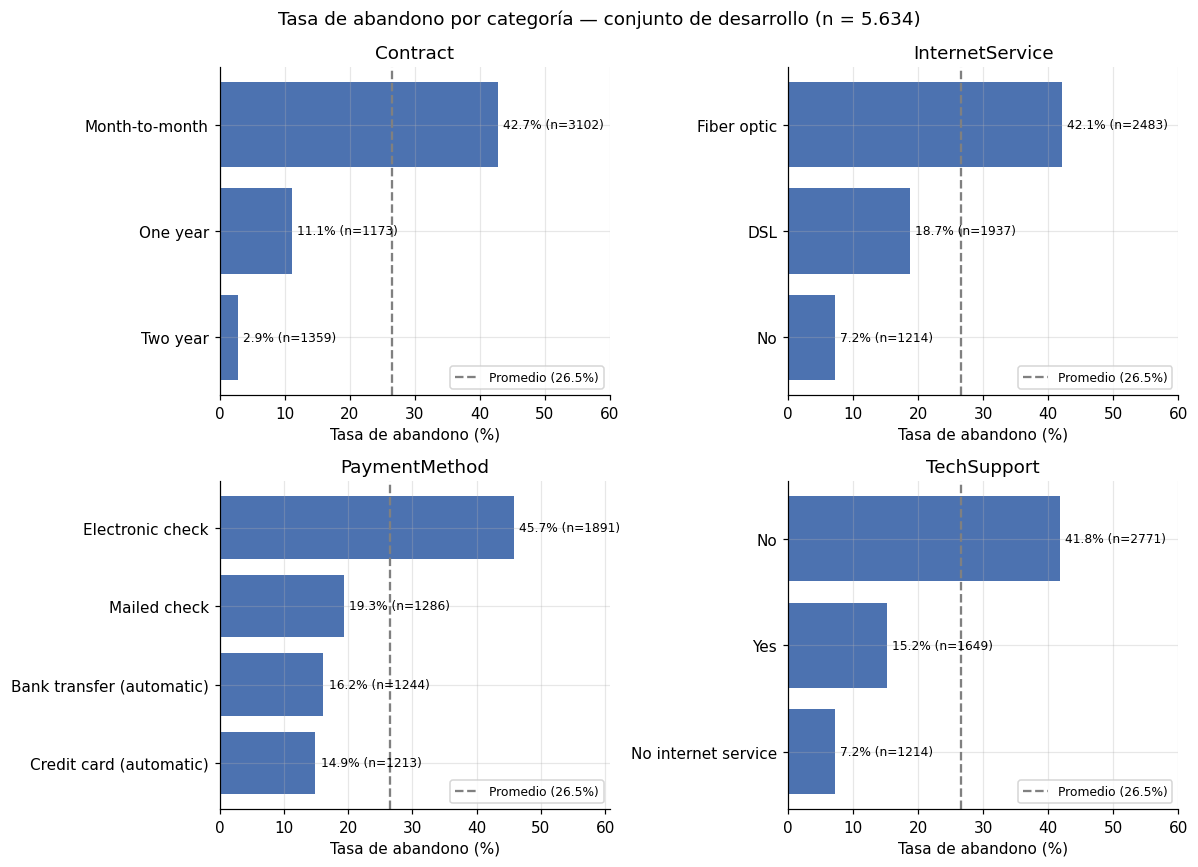

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


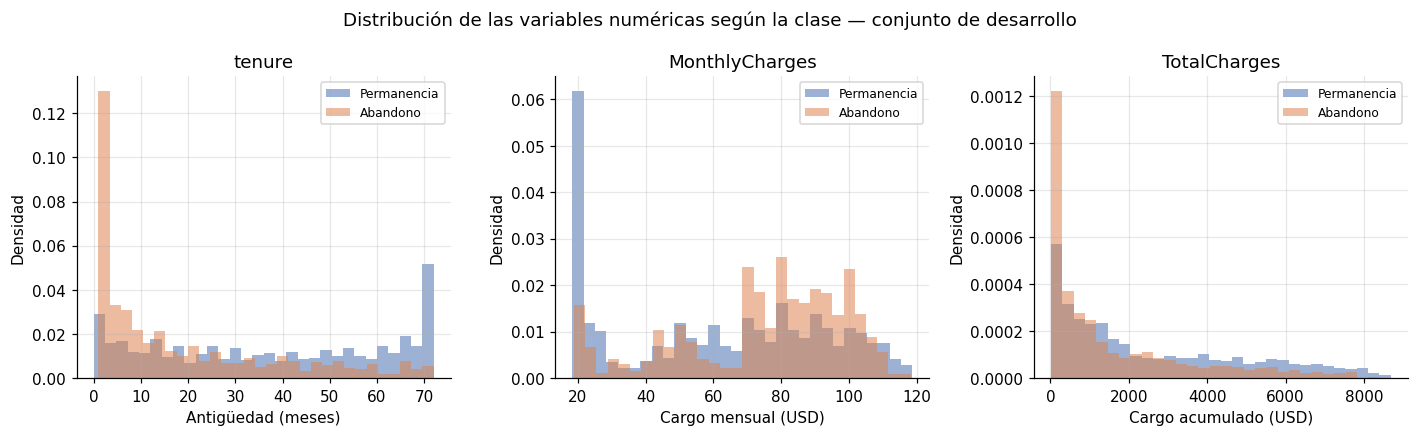

In [6]:
# --- Figura: tasa de abandono por categoría ---
variables_graficadas = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, var in zip(axes.ravel(), variables_graficadas):
    datos = tasas[tasas.variable == var].sort_values('tasa_abandono')
    ax.barh(datos.categoria.astype(str), datos.tasa_abandono * 100, color='#4C72B0')
    ax.axvline(prevalencia_dev * 100, color='gray', linestyle='--', label=f'Promedio ({prevalencia_dev:.1%})')
    for i, (tasa, n) in enumerate(zip(datos.tasa_abandono, datos.n)):
        ax.text(tasa * 100 + 0.8, i, f'{tasa:.1%} (n={n})', va='center', fontsize=8)
    ax.set_title(var)
    ax.set_xlabel('Tasa de abandono (%)')
    ax.set_xlim(0, max(60, datos.tasa_abandono.max() * 100 + 15))
    ax.legend(loc='lower right', fontsize=8)
fig.suptitle('Tasa de abandono por categoría — conjunto de desarrollo (n = 5.634)')
guardar_figura('eda_tasa_abandono_categorias.png')

# --- Figura: distribución de variables numéricas según la clase ---
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
etiquetas = {0: 'Permanencia', 1: 'Abandono'}
for ax, var in zip(axes, NUM):
    for clase, color in [(0, '#4C72B0'), (1, '#DD8452')]:
        valores = eda.loc[eda.Churn == clase, var].dropna()
        ax.hist(valores, bins=30, alpha=0.55, density=True, color=color, label=etiquetas[clase])
    ax.set_title(var)
    ax.set_xlabel({'tenure': 'Antigüedad (meses)', 'MonthlyCharges': 'Cargo mensual (USD)',
                   'TotalCharges': 'Cargo acumulado (USD)'}[var])
    ax.set_ylabel('Densidad')
    ax.legend(fontsize=8)
fig.suptitle('Distribución de las variables numéricas según la clase — conjunto de desarrollo')
guardar_figura('eda_distribucion_numericas.png')

## 5. Preprocesamiento
Todas las transformaciones están dentro de objetos `Pipeline` y `ColumnTransformer`, de modo que se ajustan **solo con los datos de entrenamiento** de cada pliegue:
- **Numéricas:** imputación por mediana y, solo en regresión logística, estandarización.
- **Categóricas:** imputación por la categoría más frecuente y codificación *one-hot*, que admite categorías no vistas.

La clase `FoldWeightedXGB` envuelve XGBoost para que el peso de la clase positiva (`scale_pos_weight`) se calcule **dentro de cada `fit`**, con las etiquetas de ese pliegue. Se escribe en un archivo propio para que el modelo guardado pueda recargarse después.

Casos de prueba: **CP-03** (imputación y matriz finita) y **CP-10** (categoría no observada).

In [7]:
MODULE = '''from sklearn.base import BaseEstimator, ClassifierMixin
import numpy as np
from xgboost import XGBClassifier


class FoldWeightedXGB(ClassifierMixin, BaseEstimator):
    """XGBoost cuyo peso de clase positiva se calcula con las etiquetas de cada fit."""

    def __init__(self, weighted=False, n_estimators=200, max_depth=3, learning_rate=0.1, subsample=1.0,
                 colsample_bytree=1.0, reg_lambda=1.0, random_state=42, n_jobs=1):
        self.weighted = weighted
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.reg_lambda = reg_lambda
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        etiquetas = np.asarray(y)
        positivos = int((etiquetas == 1).sum())
        negativos = int((etiquetas == 0).sum())
        if not positivos or not negativos:
            raise ValueError('Se requieren ambas clases')
        # Razón negativos/positivos calculada solo con el entrenamiento recibido
        self.scale_pos_weight_ = negativos / positivos if self.weighted else 1.0
        self.model_ = XGBClassifier(
            n_estimators=self.n_estimators, max_depth=self.max_depth, learning_rate=self.learning_rate,
            subsample=self.subsample, colsample_bytree=self.colsample_bytree, reg_lambda=self.reg_lambda,
            random_state=self.random_state, n_jobs=self.n_jobs, scale_pos_weight=self.scale_pos_weight_,
            objective='binary:logistic', eval_metric='logloss', tree_method='hist')
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        self.n_features_in_ = self.model_.n_features_in_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)
'''
(OUT / 'churn_estimators.py').write_text(MODULE, encoding='utf-8')
sys.path.insert(0, str(OUT.resolve()))
from churn_estimators import FoldWeightedXGB

In [8]:
def preprocessor(escalar):
    """Construye el preprocesamiento; 'escalar' solo se activa para la regresión logística."""
    pasos_numericos = [('imputer', SimpleImputer(strategy='median'))]
    if escalar:
        pasos_numericos.append(('scaler', StandardScaler()))
    pasos_categoricos = [('imputer', SimpleImputer(strategy='most_frequent')),
                         ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]
    return ColumnTransformer([('num', Pipeline(pasos_numericos), NUM),
                              ('cat', Pipeline(pasos_categoricos), CAT)])

# --- Verificaciones del preprocesamiento ---
prep_check = preprocessor(True)
transformed = prep_check.fit_transform(X_dev)
check('CP-03', 'Matriz de desarrollo finita', np.isfinite(transformed).all())
medianas_aprendidas = prep_check.named_transformers_['num'].named_steps['imputer'].statistics_
check('CP-03', 'Medianas ajustadas con desarrollo', np.allclose(medianas_aprendidas, X_dev[NUM].median().values))

prueba_entrada = X_dev.iloc[:2].copy()
prueba_entrada.loc[prueba_entrada.index[0], 'TotalCharges'] = np.nan
check('CP-03', 'Imputa faltantes en entrada', np.isfinite(prep_check.transform(prueba_entrada)).all())

prueba_entrada.loc[prueba_entrada.index[0], 'Contract'] = 'CATEGORIA_NO_OBSERVADA'
salida = prep_check.transform(prueba_entrada)
check('CP-10', 'Categoría nueva admitida sin cambiar dimensiones',
      salida.shape[1] == transformed.shape[1] and np.isfinite(salida).all())

print('Predictores originales:', len(FEATURES))
print('Columnas tras la transformación:', transformed.shape[1])
print('Valores no finitos:', int((~np.isfinite(transformed)).sum()))
quality['columnas_transformadas_desarrollo'] = int(transformed.shape[1])
json_save('calidad_fuente.json', quality)

Predictores originales: 15
Columnas tras la transformación: 38
Valores no finitos: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 6. Búsqueda de modelos y selección
Se comparan seis variantes: tres familias (LR, RF y XGB), cada una con y sin ponderación de clases.
- **Regresión logística:** los 6 valores de C.
- **Random Forest y XGBoost:** 15 combinaciones por variante, tomadas sin repetición con semilla 42. Se usan las mismas combinaciones para ambas ponderaciones.

En total son 72 configuraciones × 5 pliegues = 360 ajustes. En cada ajuste se verifica que la mediana de imputación y el peso de XGBoost provengan solo del pliegue de entrenamiento.

**Regla de selección:**
1. Se forma una banda de candidatos con AP media ≥ máximo − 0,005.
2. Dentro de la banda se elige la menor desviación estándar.
3. Si hay empate, se prefiere LR, luego RF y luego XGB, y finalmente un índice estable.

El protocolo y la selección se guardan **antes** de mirar el conjunto de prueba.

Casos de prueba: **CP-04** (auditoría por pliegue), **CP-05** (tres familias) y **CP-09** (seis variantes y pesos).

In [9]:
spaces = {
    'LR':  {'clf__C': [.001, .01, .1, 1., 10., 100.]},
    'RF':  {'clf__n_estimators': [200, 400], 'clf__max_depth': [None, 8, 16],
            'clf__min_samples_leaf': [1, 3, 5], 'clf__max_features': ['sqrt', .7]},
    'XGB': {'clf__n_estimators': [200, 400], 'clf__max_depth': [2, 3, 5], 'clf__learning_rate': [.03, .1],
            'clf__subsample': [.8, 1.], 'clf__colsample_bytree': [.8, 1.], 'clf__reg_lambda': [1., 5.]},
}
configs = {familia: list(ParameterSampler(espacio, n_iter=6 if familia == 'LR' else 15, random_state=SEED))
           for familia, espacio in spaces.items()}

def crear_estimador(familia, ponderado):
    """Devuelve el clasificador de la familia indicada, con o sin ponderación de clases."""
    if familia == 'LR':
        return LogisticRegression(C=1., solver='lbfgs', max_iter=3000,
                                  class_weight='balanced' if ponderado else None, random_state=SEED)
    if familia == 'RF':
        return RandomForestClassifier(class_weight='balanced' if ponderado else None, random_state=SEED, n_jobs=1)
    return FoldWeightedXGB(weighted=ponderado, random_state=SEED, n_jobs=1)

variants = [(familia, ponderado,
             Pipeline([('prep', preprocessor(familia == 'LR')), ('clf', crear_estimador(familia, ponderado))]))
            for familia in ['LR', 'RF', 'XGB'] for ponderado in [False, True]]

# Protocolo congelado ANTES de entrenar
json_save('protocolo_congelado.json', {
    'semilla': SEED, 'test_size': TEST_SIZE, 'pliegues': N_FOLDS, 'tolerancia_ap': TOLERANCIA_AP,
    'seleccion': 'banda respecto al máximo; menor DE; orden LR RF XGB; índice estable',
    'espacios': spaces, 'configuraciones': configs, 'permutaciones': N_PERMUTACIONES, 'bootstrap': N_BOOTSTRAP,
    'umbral': 'todos los scores OOF distintos; máximo F1; empate umbral mayor',
    'fecha_utc': datetime.now(timezone.utc).isoformat(), 'estado_prueba': 'partición conocida en versión anterior'})

In [10]:
records, candidates, fold_rows, fit_audit = [], {}, [], []

for familia, ponderado, pipe in variants:
    nombre_variante = familia + (' ponderado' if ponderado else ' sin ponderar')
    for params in configs[familia]:
        candidato = clone(pipe).set_params(**params)
        inicio = time.perf_counter()
        with joblib.parallel_backend('threading'):
            cvout = cross_validate(candidato, X_dev, y_dev, cv=folds,
                                   scoring={'AP': 'average_precision', 'ROC_AUC': 'roc_auc'},
                                   n_jobs=N_JOBS, error_score='raise', return_estimator=True)
        cid = len(records)
        candidates[cid] = candidato

        # Auditoría de cada ajuste: la imputación y el peso deben venir solo del pliegue de entrenamiento
        for k, ((idx_tr, idx_va), estimador) in enumerate(zip(folds, cvout['estimator']), 1):
            medianas = estimador.named_steps['prep'].named_transformers_['num'].named_steps['imputer'].statistics_
            assert np.allclose(medianas, X_dev.iloc[idx_tr][NUM].median().values), 'Mediana fuera del pliegue'
            peso = None
            if familia == 'XGB':
                esperado = (float((y_dev.iloc[idx_tr] == 0).sum() / (y_dev.iloc[idx_tr] == 1).sum())
                            if ponderado else 1.)
                peso = float(estimador.named_steps['clf'].scale_pos_weight_)
                assert np.isclose(peso, esperado), 'Peso fuera del pliegue'
            fit_audit.append({'id': cid, 'pliegue': k, 'n_entrenamiento': len(idx_tr), 'medianas': medianas.tolist(),
                              'peso_xgb': peso, 'sin_interseccion': len(set(idx_tr) & set(idx_va)) == 0})
            fold_rows.append({'id': cid, 'variante': nombre_variante, 'pliegue': k,
                              'AP': float(cvout['test_AP'][k - 1]), 'ROC_AUC': float(cvout['test_ROC_AUC'][k - 1])})

        records.append({'id': cid, 'familia': familia, 'variante': nombre_variante, 'ponderado': ponderado,
                        'AP_media': float(np.mean(cvout['test_AP'])), 'AP_DE': float(np.std(cvout['test_AP'])),
                        'ROC_AUC_media': float(np.mean(cvout['test_ROC_AUC'])),
                        'segundos': time.perf_counter() - inicio, 'parametros': json.dumps(params, sort_keys=True)})
        del cvout
    print(f'{nombre_variante:<17} completado', flush=True)

results = pd.DataFrame(records)
results.to_csv(OUT / 'busqueda_completa.csv', index=False)
pd.DataFrame(fold_rows).to_csv(OUT / 'metricas_por_pliegue.csv', index=False)
json_save('auditoria_fit_pliegues.json', fit_audit)

check('CP-04', 'Imputación verificada en cada fit de validación', len(fit_audit) == len(results) * N_FOLDS)
check('CP-09', 'Seis variantes y pesos verificados por pliegue', results.variante.nunique() == 6)
check('CP-05', 'Tres familias con métricas CV finitas',
      results.familia.nunique() == 3 and np.isfinite(results[['AP_media', 'ROC_AUC_media']]).all().all())

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are

LR sin ponderar   completado


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.

LR ponderado      completado


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
<sys>:0: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7d4653171a90>
<sys>:0: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7d4653171080>
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-

RF sin ponderar   completado


... (3 outputs left out)

XGB sin ponderar  completado


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

XGB ponderado     completado


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [11]:
# --- Mejor configuración de cada variante (Tabla N°9 del informe) ---
summary = results.loc[results.groupby('variante', sort=False).AP_media.idxmax()].copy()
summary.to_csv(OUT / 'resumen_variantes.csv', index=False)

# --- Regla de selección global ---
max_ap = results.AP_media.max()
eligible = results.loc[results.AP_media >= max_ap - TOLERANCIA_AP].copy()
eligible['orden_familia'] = eligible.familia.map({'LR': 0, 'RF': 1, 'XGB': 2})
selected = eligible.sort_values(['AP_DE', 'orden_familia', 'id']).iloc[0]
winner = clone(candidates[int(selected.id)])

json_save('seleccion_modelo.json', {'seleccionado': selected.to_dict(), 'max_AP_observada': float(max_ap),
                                     'candidatos_en_banda': len(eligible),
                                     'congelado_utc': datetime.now(timezone.utc).isoformat()})

print(summary[['variante', 'AP_media', 'AP_DE', 'ROC_AUC_media']].round(4).to_string(index=False))
print(f'\nCandidatos dentro de la banda de tolerancia: {len(eligible)}')
print(f'SELECCIONADO: {selected.variante} | AP media = {selected.AP_media:.4f} | DE = {selected.AP_DE:.4f}')
print('Parámetros:', selected.parametros)

        variante  AP_media  AP_DE  ROC_AUC_media
 LR sin ponderar    0.6599 0.0184         0.8460
    LR ponderado    0.6580 0.0189         0.8458
 RF sin ponderar    0.6656 0.0197         0.8481
    RF ponderado    0.6654 0.0198         0.8446
XGB sin ponderar    0.6712 0.0214         0.8502
   XGB ponderado    0.6701 0.0211         0.8496

Candidatos dentro de la banda de tolerancia: 11
SELECCIONADO: XGB sin ponderar | AP media = 0.6679 | DE = 0.0199
Parámetros: {"clf__colsample_bytree": 0.8, "clf__learning_rate": 0.03, "clf__max_depth": 5, "clf__n_estimators": 200, "clf__reg_lambda": 5.0, "clf__subsample": 0.8}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 7. Análisis de sensibilidad entre pliegues
Es la comprobación descriptiva prometida en la sección 3.6.4. Responde tres preguntas usando solo la validación cruzada:
1. ¿Se mantiene el orden de las variantes en los cinco pliegues?
2. ¿Cuánto cambia la AP al ponderar las clases?
3. ¿Cuánto supera el modelo seleccionado a la mejor regresión logística? Esta es la comparación adicional de la hipótesis.

Se usa la mejor configuración de cada variante y la configuración seleccionada. **No modifica la selección**, que ya quedó congelada.

In [12]:
por_pliegue = pd.DataFrame(fold_rows)

# AP por pliegue de la mejor configuración de cada variante y de la configuración seleccionada
ids_resumen = dict(zip(summary.variante, summary.id))
ids_resumen['Seleccionado'] = int(selected.id)
tabla_pliegues = pd.DataFrame({nombre: por_pliegue[por_pliegue.id == cid].set_index('pliegue').AP
                               for nombre, cid in ids_resumen.items()})
tabla_pliegues.to_csv(OUT / 'sensibilidad_ap_por_pliegue.csv')

# 1) Orden de las seis variantes en cada pliegue (1 = mejor AP)
rangos = tabla_pliegues.drop(columns='Seleccionado').rank(axis=1, ascending=False).astype(int)
rangos.to_csv(OUT / 'sensibilidad_rangos.csv')

# 2) Efecto de la ponderación: AP ponderada − AP sin ponderar, por familia y pliegue
efecto_ponderacion = pd.DataFrame({fam: tabla_pliegues[f'{fam} ponderado'] - tabla_pliegues[f'{fam} sin ponderar']
                                   for fam in ['LR', 'RF', 'XGB']})
efecto_ponderacion.to_csv(OUT / 'sensibilidad_efecto_ponderacion.csv')

# 3) Seleccionado frente a la mejor regresión logística
mejor_lr = summary[summary.familia == 'LR'].sort_values('AP_media').iloc[-1]
dif_vs_lr = tabla_pliegues['Seleccionado'] - tabla_pliegues[mejor_lr.variante]

sensibilidad = {
    'rango_medio_por_variante': rangos.mean().round(2).to_dict(),
    'pliegues_en_que_cada_variante_es_la_mejor': (rangos == 1).sum().to_dict(),
    'efecto_ponderacion_medio': efecto_ponderacion.mean().to_dict(),
    'efecto_ponderacion_min_max': {f: [float(efecto_ponderacion[f].min()), float(efecto_ponderacion[f].max())]
                                   for f in efecto_ponderacion},
    'mejor_regresion_logistica': mejor_lr.variante,
    'diferencia_media_seleccionado_vs_LR': float(dif_vs_lr.mean()),
    'diferencia_DE_seleccionado_vs_LR': float(dif_vs_lr.std(ddof=1)),
    'pliegues_en_que_seleccionado_supera_LR': int((dif_vs_lr > 0).sum()),
}
json_save('sensibilidad_resumen.json', sensibilidad)

print('AP por pliegue:')
print(tabla_pliegues.round(4).to_string())
print('\nRango de cada variante por pliegue (1 = mejor):')
print(rangos.to_string())
print('\nEfecto de la ponderación (AP ponderada − AP sin ponderar):')
print(efecto_ponderacion.round(4).to_string())
print(f"\nSeleccionado − {mejor_lr.variante}: media {dif_vs_lr.mean():.4f}, "
      f"lo supera en {(dif_vs_lr > 0).sum()} de {N_FOLDS} pliegues")

AP por pliegue:
         LR sin ponderar  LR ponderado  RF sin ponderar  RF ponderado  XGB sin ponderar  XGB ponderado  Seleccionado
pliegue                                                                                                             
1                 0.6442        0.6404           0.6502        0.6510            0.6602         0.6585        0.6551
2                 0.6343        0.6320           0.6372        0.6383            0.6357         0.6348        0.6373
3                 0.6822        0.6814           0.6932        0.6960            0.6978         0.6940        0.6951
4                 0.6766        0.6734           0.6719        0.6748            0.6826         0.6819        0.6768
5                 0.6624        0.6630           0.6754        0.6666            0.6797         0.6813        0.6754

Rango de cada variante por pliegue (1 = mejor):
         LR sin ponderar  LR ponderado  RF sin ponderar  RF ponderado  XGB sin ponderar  XGB ponderado
pliegue      

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


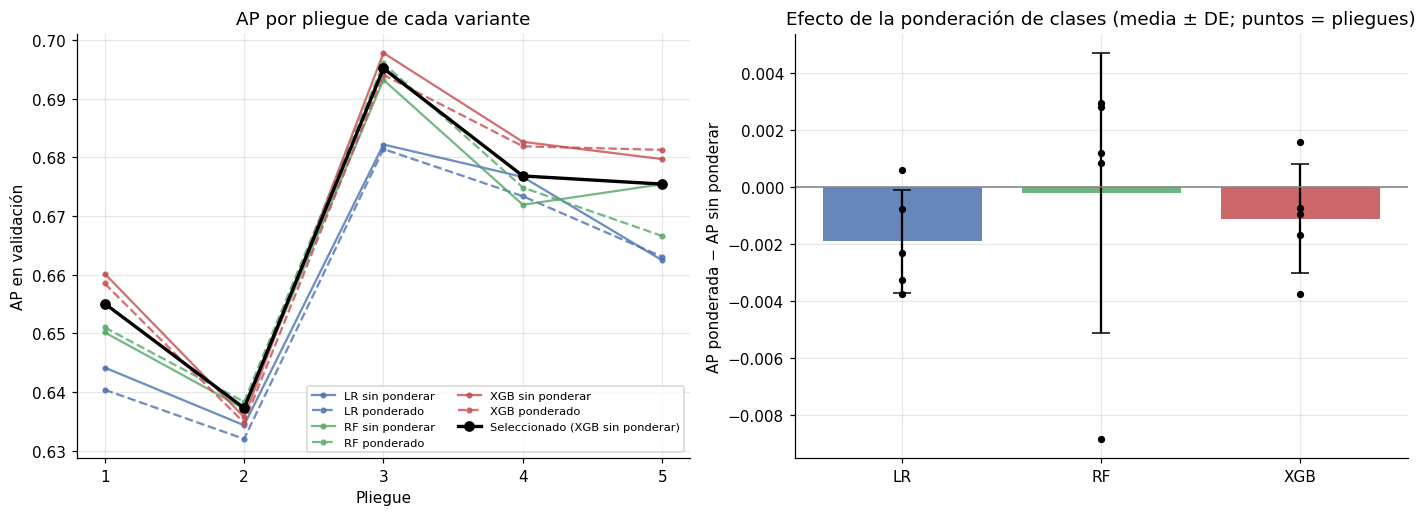

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Izquierda: AP de cada variante en cada pliegue
colores = {'LR': '#4C72B0', 'RF': '#55A868', 'XGB': '#C44E52'}
for columna in tabla_pliegues.columns:
    if columna == 'Seleccionado':
        axes[0].plot(tabla_pliegues.index, tabla_pliegues[columna], color='black', linewidth=2.2,
                     marker='o', label='Seleccionado (XGB sin ponderar)')
    else:
        familia = columna.split()[0]
        axes[0].plot(tabla_pliegues.index, tabla_pliegues[columna], color=colores[familia],
                     linestyle='--' if 'ponderado' in columna and 'sin' not in columna else '-',
                     marker='.', alpha=0.8, label=columna)
axes[0].set_xticks(range(1, N_FOLDS + 1))
axes[0].set_xlabel('Pliegue')
axes[0].set_ylabel('AP en validación')
axes[0].set_title('AP por pliegue de cada variante')
axes[0].legend(fontsize=7.5, ncol=2)

# Derecha: efecto de la ponderación por familia
posiciones = np.arange(3)
axes[1].bar(posiciones, efecto_ponderacion.mean(), yerr=efecto_ponderacion.std(ddof=1), capsize=6,
            color=[colores[f] for f in efecto_ponderacion.columns], alpha=0.85)
for i, familia in enumerate(efecto_ponderacion.columns):
    axes[1].scatter(np.full(N_FOLDS, i), efecto_ponderacion[familia], color='black', s=14, zorder=3)
axes[1].axhline(0, color='gray', linewidth=1)
axes[1].set_xticks(posiciones, efecto_ponderacion.columns)
axes[1].set_ylabel('AP ponderada − AP sin ponderar')
axes[1].set_title('Efecto de la ponderación de clases (media ± DE; puntos = pliegues)')
guardar_figura('sensibilidad_pliegues.png')

## 8. Umbral de clasificación
Con el modelo ya elegido se generan predicciones **fuera de pliegue (OOF)** sobre el desarrollo: cada registro es predicho por un modelo que no lo usó para entrenar. El umbral elegido es el que maximiza F1 y, si hay empate, se toma el mayor. El umbral se guarda **antes** de evaluar la prueba.

Además se muestra una **tabla de umbrales alternativos**, también con predicciones OOF, para ver el compromiso entre precisión, exhaustividad y volumen de alertas. Es descriptiva y no cambia el umbral congelado.

Caso de prueba: **CP-11**.

In [14]:
# OOF para fijar el umbral. No es una evaluación externa: el desarrollo ya se usó en la búsqueda.
with joblib.parallel_backend('threading'):
    oof = cross_val_predict(winner, X_dev, y_dev, cv=folds, method='predict_proba', n_jobs=N_JOBS)[:, 1]

prec, rec, thresholds = precision_recall_curve(y_dev, oof)
f1_candidates = np.divide(2 * prec[:-1] * rec[:-1], prec[:-1] + rec[:-1],
                          out=np.zeros(len(thresholds)), where=(prec[:-1] + rec[:-1]) != 0)
max_f1 = f1_candidates.max()
ties = np.flatnonzero(np.isclose(f1_candidates, max_f1, rtol=0, atol=1e-12))
threshold = float(thresholds[ties[-1]])     # En caso de empate se elige el umbral mayor

check('CP-11', 'Todos los registros tienen una predicción OOF y umbral válido',
      len(oof) == len(y_dev) and np.isfinite(oof).all() and 0 <= threshold <= 1)

pd.DataFrame({'fila_fuente': X_dev.index, 'y': y_dev.values, 'score_oof': oof}).to_csv(OUT / 'predicciones_oof.csv', index=False)
pd.DataFrame({'umbral': thresholds, 'F1': f1_candidates}).to_csv(OUT / 'busqueda_umbral.csv', index=False)
json_save('umbral_congelado.json', {'umbral': threshold, 'F1_oof_desarrollo': float(max_f1), 'empates': len(ties),
                                    'fecha_utc': datetime.now(timezone.utc).isoformat()})
print(f'Umbral congelado: {threshold:.6f} | F1 OOF de desarrollo: {max_f1:.4f}')

Umbral congelado: 0.301863 | F1 OOF de desarrollo: 0.6352


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


 umbral  precision  exhaustividad     F1  alertas_pct  alertas_por_1000_clientes  elegido
 0.2000     0.4807         0.8515 0.6145      47.0004                   470.0035    False
 0.2500     0.5127         0.7993 0.6247      41.3738                   413.7380    False
 0.3019     0.5469         0.7565 0.6349      36.7057                   367.0572     True
 0.3500     0.5721         0.6950 0.6276      32.2329                   322.3287    False
 0.4000     0.6196         0.6482 0.6335      27.7600                   277.6003    False
 0.5000     0.6720         0.5291 0.5921      20.8910                   208.9102    False
 0.6000     0.7141         0.3893 0.5039      14.4657                   144.6574    False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


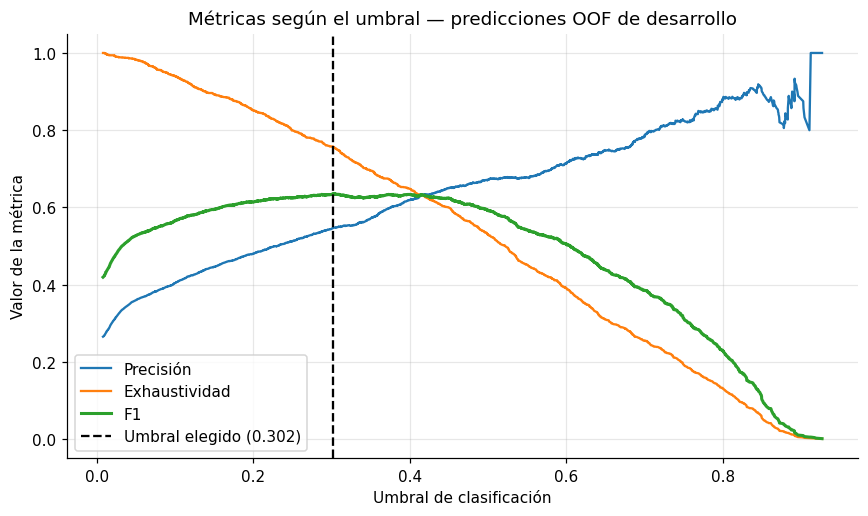

In [15]:
# --- Tabla de umbrales alternativos (solo OOF de desarrollo, descriptiva) ---
def resumen_umbral(etiquetas, puntajes, umbral):
    prediccion = (puntajes >= umbral).astype(int)
    return {'umbral': umbral,
            'precision': precision_score(etiquetas, prediccion, zero_division=0),
            'exhaustividad': recall_score(etiquetas, prediccion, zero_division=0),
            'F1': f1_score(etiquetas, prediccion, zero_division=0),
            'alertas_pct': prediccion.mean() * 100,
            'alertas_por_1000_clientes': prediccion.mean() * 1000}

umbrales_alternativos = sorted({0.20, 0.25, 0.35, 0.40, 0.50, 0.60, round(threshold, 4)})
tabla_umbrales = pd.DataFrame([resumen_umbral(y_dev, oof, u) for u in umbrales_alternativos])
tabla_umbrales['elegido'] = np.isclose(tabla_umbrales.umbral, round(threshold, 4))
tabla_umbrales.to_csv(OUT / 'umbrales_alternativos_oof.csv', index=False)
print(tabla_umbrales.round(4).to_string(index=False))

# Figura: precisión, exhaustividad y F1 según el umbral (OOF)
plt.figure(figsize=(8, 4.8))
plt.plot(thresholds, prec[:-1], label='Precisión')
plt.plot(thresholds, rec[:-1], label='Exhaustividad')
plt.plot(thresholds, f1_candidates, label='F1', linewidth=2)
plt.axvline(threshold, color='black', linestyle='--', label=f'Umbral elegido ({threshold:.3f})')
plt.xlabel('Umbral de clasificación')
plt.ylabel('Valor de la métrica')
plt.title('Métricas según el umbral — predicciones OOF de desarrollo')
plt.legend()
guardar_figura('umbral_metricas_oof.png')

## 9. Evaluación final en el conjunto de prueba
El modelo seleccionado se reajusta con todo el desarrollo y se evalúa **una sola vez** en la prueba, junto con la referencia `DummyClassifier(strategy='prior')`. AP y ROC-AUC usan los puntajes continuos; las demás métricas usan el umbral congelado.

Casos de prueba: **CP-05**, **CP-06** y **CP-07**.

In [16]:
winner.fit(X_dev, y_dev)
baseline = Pipeline([('prep', preprocessor(False)), ('clf', DummyClassifier(strategy='prior'))]).fit(X_dev, y_dev)

scores = winner.predict_proba(X_test)[:, 1]
pred = (scores >= threshold).astype(int)
base_scores = baseline.predict_proba(X_test)[:, 1]
base_pred = baseline.predict(X_test)

check('CP-05', 'Una predicción finita entre 0 y 1 por fila',
      len(scores) == len(X_test) and np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all())
check('CP-06', 'Referencia constante e igual al prior de desarrollo', np.allclose(base_scores, y_dev.mean()))

def calcular_metricas(etiquetas, puntajes, prediccion):
    return {'AP': average_precision_score(etiquetas, puntajes),
            'ROC_AUC': roc_auc_score(etiquetas, puntajes),
            'Exactitud': accuracy_score(etiquetas, prediccion),
            'Precision': precision_score(etiquetas, prediccion, zero_division=0),
            'Recall': recall_score(etiquetas, prediccion, zero_division=0),
            'F1': f1_score(etiquetas, prediccion, zero_division=0)}

m = calcular_metricas(y_test, scores, pred)              # Modelo seleccionado
mb = calcular_metricas(y_test, base_scores, base_pred)    # Referencia
comparison = pd.DataFrame([{'modelo': 'Referencia', **mb}, {'modelo': selected.variante, **m}])
comparison.to_csv(OUT / 'metricas_prueba.csv', index=False)
pd.DataFrame({'fila_fuente': X_test.index, 'y': y_test.values, 'score_modelo': scores, 'prediccion': pred,
              'score_referencia': base_scores, 'prediccion_referencia': base_pred}
             ).to_csv(OUT / 'predicciones_prueba.csv', index=False)
check('CP-07', 'Seis métricas finitas por modelo', np.isfinite(comparison.drop(columns='modelo')).all().all())
print(comparison.round(4).to_string(index=False))

# --- Comparación con las metas de la Tabla N°6 del informe ---
metas = pd.DataFrame([
    ('AP',        '≥ 0,60',         m['AP'],        m['AP'] >= 0.60),
    ('ROC-AUC',   '≥ 0,80',         m['ROC_AUC'],   m['ROC_AUC'] >= 0.80),
    ('Exhaustividad', '≥ 0,70',     m['Recall'],    m['Recall'] >= 0.70),
    ('Precisión', '≥ 0,50',         m['Precision'], m['Precision'] >= 0.50),
    ('F1',        '≥ 0,58',         m['F1'],        m['F1'] >= 0.58),
    ('Exactitud', '> referencia',   m['Exactitud'], m['Exactitud'] > mb['Exactitud']),
], columns=['metrica', 'meta', 'obtenido', 'cumple'])
metas.to_csv(OUT / 'metas_vs_obtenido.csv', index=False)
print('\nMetas frente a lo obtenido:')
print(metas.round(4).to_string(index=False))

          modelo     AP  ROC_AUC  Exactitud  Precision  Recall     F1
      Referencia 0.2654   0.5000     0.7346     0.0000  0.0000 0.0000
XGB sin ponderar 0.6607   0.8463     0.7630     0.5379  0.7594 0.6297

Metas frente a lo obtenido:
      metrica         meta  obtenido  cumple
           AP       ≥ 0,60    0.6607    True
      ROC-AUC       ≥ 0,80    0.8463    True
Exhaustividad       ≥ 0,70    0.7594    True
    Precisión       ≥ 0,50    0.5379    True
           F1       ≥ 0,58    0.6297    True
    Exactitud > referencia    0.7630    True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 10. Contraste de hipótesis: bootstrap de ΔAP
ΔAP es la AP del modelo menos la AP de la referencia, calculada sobre los mismos clientes de prueba. En cada una de las 2.000 remuestras se toma, con reemplazo, el mismo número de positivos y de negativos que tiene la prueba (remuestreo estratificado), y ambos métodos se evalúan con los mismos índices (remuestreo pareado). El intervalo de confianza del 95 % se obtiene con los percentiles 2,5 y 97,5.

**H1 se apoya si se cumplen dos condiciones:** el límite inferior es mayor que 0 **y** la AP alcanza al menos 0,60. Como la partición ya era conocida, es un contraste condicional y descriptivo.

{
  "delta_AP": 0.39527358306527555,
  "IC95_inferior": 0.35270388113897566,
  "IC95_superior": 0.4390724284884555,
  "AP_modelo": 0.6607100628381641,
  "meta_AP": 0.6,
  "decision_condicional": "Evidencia a favor de H1 en esta reevaluación interna",
  "n_remuestras": 2000,
  "nota": "Intervalo condicionado al modelo y composición de prueba. Partición ya conocida: no constituye confirmación independiente."
}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


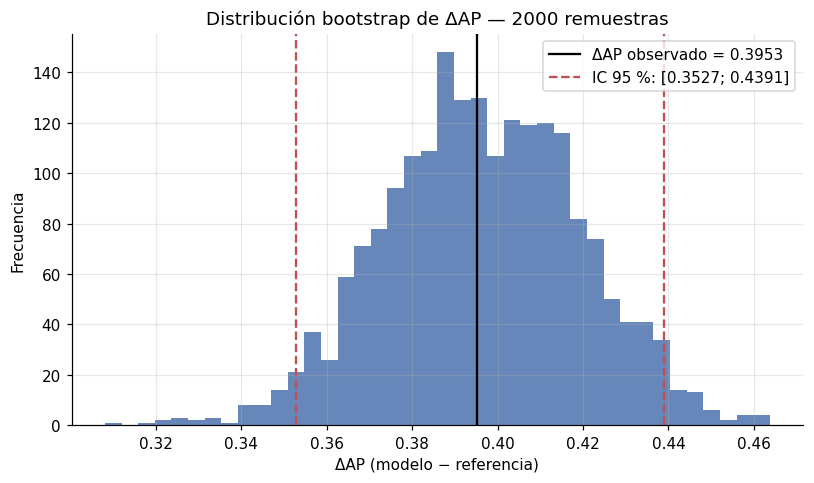

In [17]:
rng = np.random.RandomState(SEED)
y_array = y_test.to_numpy()
pos = np.flatnonzero(y_array == 1)
neg = np.flatnonzero(y_array == 0)

deltas = []
for _ in range(N_BOOTSTRAP):
    ids = np.r_[rng.choice(pos, len(pos), replace=True), rng.choice(neg, len(neg), replace=True)]
    deltas.append(average_precision_score(y_array[ids], scores[ids]) -
                  average_precision_score(y_array[ids], base_scores[ids]))

lo, hi = np.percentile(deltas, [2.5, 97.5])
delta = m['AP'] - mb['AP']
h1_apoyada = (lo > 0) and (m['AP'] >= 0.60)
stat_decision = ('Evidencia a favor de H1 en esta reevaluación interna' if h1_apoyada
                 else 'No se rechaza H0 en esta reevaluación interna')
check('CP-07', 'Intervalo finito y 2000 remuestras', len(deltas) == N_BOOTSTRAP and np.isfinite([lo, hi]).all())

pd.DataFrame({'delta_AP': deltas}).to_csv(OUT / 'bootstrap_delta_AP.csv', index=False)
bootstrap = {'delta_AP': delta, 'IC95_inferior': float(lo), 'IC95_superior': float(hi),
             'AP_modelo': m['AP'], 'meta_AP': 0.60, 'decision_condicional': stat_decision,
             'n_remuestras': N_BOOTSTRAP,
             'nota': 'Intervalo condicionado al modelo y composición de prueba. Partición ya conocida: '
                     'no constituye confirmación independiente.'}
json_save('bootstrap_resumen.json', bootstrap)
print(json.dumps(bootstrap, ensure_ascii=False, indent=2))

# Figura: distribución bootstrap de ΔAP
plt.figure(figsize=(7.5, 4.5))
plt.hist(deltas, bins=40, color='#4C72B0', alpha=0.85)
plt.axvline(delta, color='black', label=f'ΔAP observado = {delta:.4f}')
plt.axvline(lo, color='#C44E52', linestyle='--', label=f'IC 95 %: [{lo:.4f}; {hi:.4f}]')
plt.axvline(hi, color='#C44E52', linestyle='--')
plt.xlabel('ΔAP (modelo − referencia)')
plt.ylabel('Frecuencia')
plt.title(f'Distribución bootstrap de ΔAP — {N_BOOTSTRAP} remuestras')
plt.legend()
guardar_figura('bootstrap_delta_ap.png')

## 11. Análisis de errores, importancia de variables y calibración
Todo este bloque es **posterior al congelamiento** y no se usa para reentrenar ni cambiar el modelo.
- **Errores:** perfil agregado de verdaderos positivos (VP), falsos negativos (FN), falsos positivos (FP) y verdaderos negativos (VN), sin perfiles individuales.
- **Importancia por permutación:** caída de AP al desordenar cada variable, con 30 repeticiones. No implica causalidad, y las variables correlacionadas pueden repartirse la importancia.
- **Calibración:** se compara la probabilidad predicha con la frecuencia real de abandono (curva de calibración y puntaje de Brier). Sirve para saber si los puntajes pueden leerse como probabilidades.
- **Serialización:** el modelo se guarda y se recarga para verificar que entrega las mismas predicciones (**CP-08**).

In [18]:
cm = confusion_matrix(y_test, pred, labels=[0, 1])
tn, fp, fn, tp = map(int, cm.ravel())
json_save('matriz_confusion.json', {'VN': tn, 'FP': fp, 'FN': fn, 'VP': tp})
print('Matriz de confusión (filas = clase observada, columnas = clase predicha):')
print(pd.DataFrame(cm, index=['Permanencia', 'Abandono'], columns=['Pred. permanencia', 'Pred. abandono']))

errores = X_test.copy()
errores['grupo'] = np.select([(y_test == 1) & (pred == 1), (y_test == 1) & (pred == 0), (y_test == 0) & (pred == 1)],
                             ['VP', 'FN', 'FP'], default='VN')
profile = errores.groupby('grupo').agg(casos=('tenure', 'size'),
                                       antiguedad_mediana=('tenure', 'median'),
                                       cargo_mediana=('MonthlyCharges', 'median'),
                                       contrato_mensual_pct=('Contract', lambda s: 100 * s.eq('Month-to-month').mean()))
profile.to_csv(OUT / 'perfil_errores.csv')
print('\nPerfil agregado de aciertos y errores:')
print(profile.round(2).to_string())

Matriz de confusión (filas = clase observada, columnas = clase predicha):
             Pred. permanencia  Pred. abandono
Permanencia                791             244
Abandono                    90             284

Perfil agregado de aciertos y errores:
       casos  antiguedad_mediana  cargo_mediana  contrato_mensual_pct
grupo                                                                
FN        90                31.5          66.38                 53.33
FP       244                12.0          79.22                 94.67
VN       791                48.0          56.30                 26.93
VP       284                 4.0          77.75                 98.94


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [19]:
with joblib.parallel_backend('threading'):
    imp = permutation_importance(winner, X_test, y_test, scoring='average_precision',
                                 n_repeats=N_PERMUTACIONES, random_state=SEED, n_jobs=N_JOBS)
importance = (pd.DataFrame({'variable': FEATURES, 'caida_AP_media': imp.importances_mean, 'DE': imp.importances_std})
              .sort_values('caida_AP_media', ascending=False))
importance.to_csv(OUT / 'importancia_variables.csv', index=False)
print(importance.round(4).to_string(index=False))

# --- Serialización y recarga (CP-08) ---
joblib.dump(winner, OUT / 'modelo_churn.joblib')
reloaded = joblib.load(OUT / 'modelo_churn.joblib')
scores_recargado = reloaded.predict_proba(X_test)[:, 1]
error_max = float(np.max(np.abs(scores - scores_recargado)))
check('CP-08', 'Recarga con diferencia absoluta <= 1e-8', np.allclose(scores, scores_recargado, atol=1e-8, rtol=0))
json_save('serializacion.json', {'error_absoluto_maximo': error_max, 'tolerancia_absoluta': 1e-8, 'tolerancia_relativa': 0})
print(f'\nDiferencia máxima de predicciones tras recargar el modelo: {error_max}')

        variable  caida_AP_media     DE
          tenure          0.1080 0.0138
        Contract          0.0972 0.0107
    TotalCharges          0.0355 0.0069
     TechSupport          0.0231 0.0068
 InternetService          0.0218 0.0094
  OnlineSecurity          0.0195 0.0065
  MonthlyCharges          0.0113 0.0102
PaperlessBilling          0.0086 0.0083
   PaymentMethod          0.0081 0.0039
    OnlineBackup          0.0045 0.0026
 StreamingMovies          0.0031 0.0025
   MultipleLines          0.0026 0.0055
    PhoneService          0.0022 0.0007
DeviceProtection         -0.0005 0.0005
     StreamingTV         -0.0015 0.0013

Diferencia máxima de predicciones tras recargar el modelo: 0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Puntaje de Brier — modelo: 0.1352 | referencia: 0.1950 | mejora relativa: 30.6%

Calibración por decil de riesgo (prueba):
 decil  probabilidad_media_predicha  frecuencia_observada_abandono  diferencia
     1                       0.0122                         0.0071      0.0051
     2                       0.0222                         0.0071      0.0151
     3                       0.0419                         0.0496     -0.0077
     4                       0.0816                         0.0993     -0.0177
     5                       0.1403                         0.1702     -0.0299
     6                       0.2209                         0.2286     -0.0077
     7                       0.3302                         0.3759     -0.0457
     8                       0.4502                         0.3617      0.0885
     9                       0.5805                         0.6099     -0.0294
    10                       0.7787                         0.7447      0.0340


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


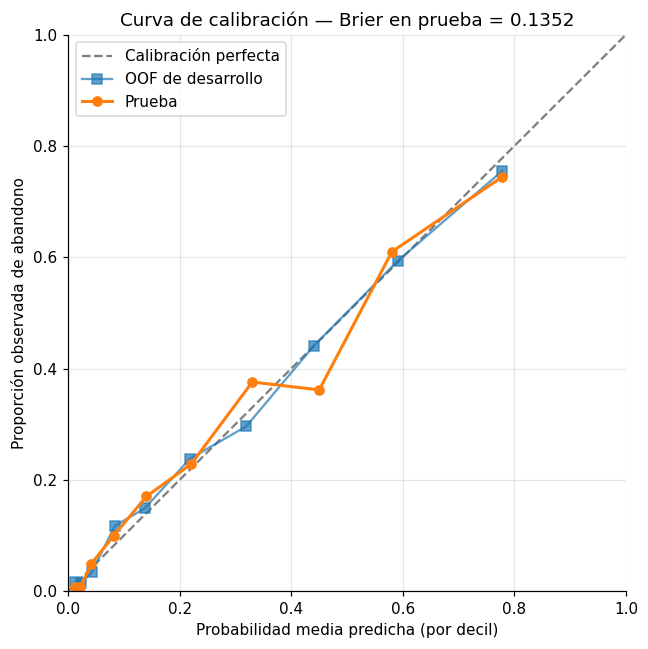

In [20]:
# --- Calibración (descriptiva) ---
brier_modelo = brier_score_loss(y_test, scores)
brier_referencia = brier_score_loss(y_test, base_scores)
frac_pos_prueba, prob_media_prueba = calibration_curve(y_test, scores, n_bins=10, strategy='quantile')
frac_pos_oof, prob_media_oof = calibration_curve(y_dev, oof, n_bins=10, strategy='quantile')

tabla_calibracion = pd.DataFrame({'decil': range(1, len(prob_media_prueba) + 1),
                                  'probabilidad_media_predicha': prob_media_prueba,
                                  'frecuencia_observada_abandono': frac_pos_prueba})
tabla_calibracion['diferencia'] = tabla_calibracion.probabilidad_media_predicha - tabla_calibracion.frecuencia_observada_abandono
tabla_calibracion.to_csv(OUT / 'calibracion_prueba.csv', index=False)
json_save('calibracion_resumen.json', {
    'brier_modelo_prueba': brier_modelo, 'brier_referencia_prueba': brier_referencia,
    'brier_skill_score': 1 - brier_modelo / brier_referencia,
    'error_absoluto_medio_por_decil': float(tabla_calibracion.diferencia.abs().mean()),
    'nota': 'Descriptivo y posterior al congelamiento; no se recalibró el modelo.'})

print(f'Puntaje de Brier — modelo: {brier_modelo:.4f} | referencia: {brier_referencia:.4f} '
      f'| mejora relativa: {1 - brier_modelo / brier_referencia:.1%}')
print('\nCalibración por decil de riesgo (prueba):')
print(tabla_calibracion.round(4).to_string(index=False))

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Calibración perfecta')
plt.plot(prob_media_oof, frac_pos_oof, marker='s', alpha=0.7, label='OOF de desarrollo')
plt.plot(prob_media_prueba, frac_pos_prueba, marker='o', linewidth=2, label='Prueba')
plt.xlabel('Probabilidad media predicha (por decil)')
plt.ylabel('Proporción observada de abandono')
plt.title(f'Curva de calibración — Brier en prueba = {brier_modelo:.4f}')
plt.legend()
plt.xlim(0, 1); plt.ylim(0, 1)
guardar_figura('curva_calibracion.png')

## 12. Figuras de resultados
Son las tres figuras del Capítulo IV: la curva precisión–exhaustividad, la matriz de confusión y la importancia por permutación.

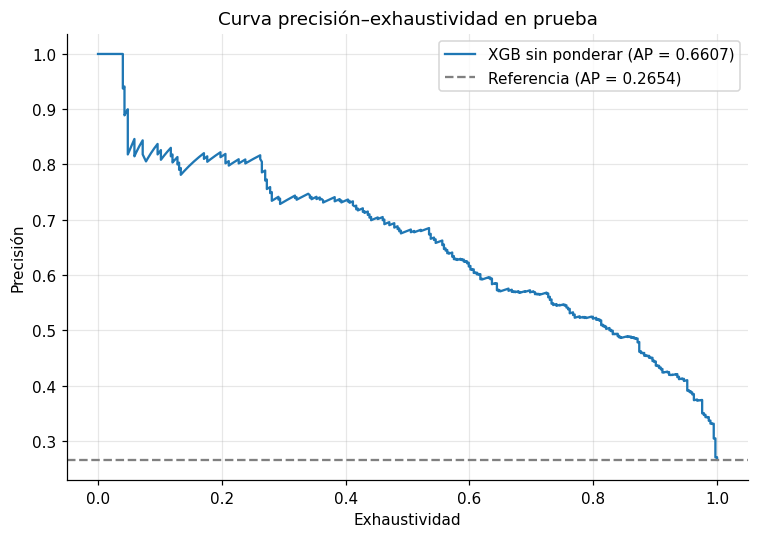

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


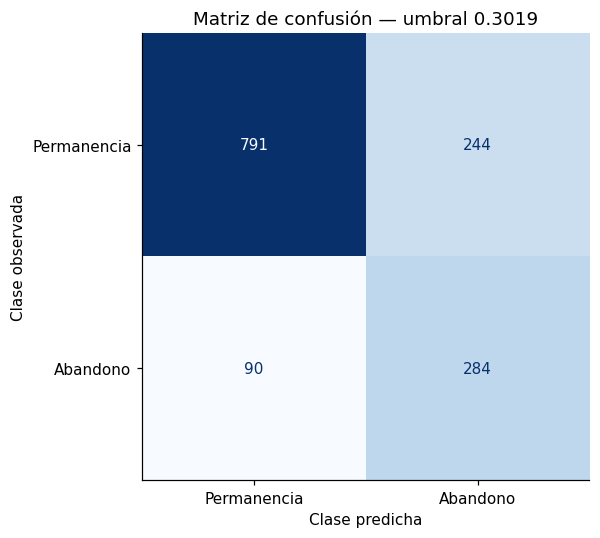

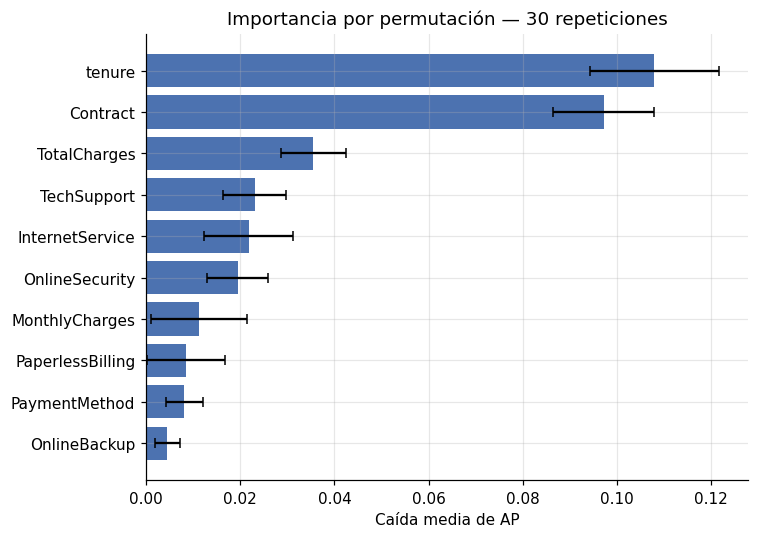

In [21]:
# Curva precisión–exhaustividad en prueba
p, r, _ = precision_recall_curve(y_test, scores)
plt.figure(figsize=(7, 5))
plt.plot(r, p, label=f'{selected.variante} (AP = {m["AP"]:.4f})')
plt.axhline(mb['AP'], linestyle='--', color='gray', label=f'Referencia (AP = {mb["AP"]:.4f})')
plt.xlabel('Exhaustividad')
plt.ylabel('Precisión')
plt.title('Curva precisión–exhaustividad en prueba')
plt.legend()
guardar_figura('curva_precision_exhaustividad.png')

# Matriz de confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['Permanencia', 'Abandono']).plot(ax=ax, colorbar=False, cmap='Blues')
ax.grid(False)
ax.set_xlabel('Clase predicha')
ax.set_ylabel('Clase observada')
ax.set_title(f'Matriz de confusión — umbral {threshold:.4f}')
guardar_figura('matriz_confusion.png')

# Importancia por permutación (10 variables principales)
top = importance.head(10).sort_values('caida_AP_media')
plt.figure(figsize=(7, 5))
plt.barh(top.variable, top.caida_AP_media, xerr=top.DE, color='#4C72B0', capsize=3)
plt.xlabel('Caída media de AP')
plt.title(f'Importancia por permutación — {N_PERMUTACIONES} repeticiones')
guardar_figura('importancia_variables.png')

## 13. Pruebas de rendimiento y reproducibilidad
Son los casos agregados tras la revisión del profesor guía:
- **CP-13 (RNF-02):** la ejecución completa debe durar menos de 600 s.
- **CP-14 (RNF-01):** los índices de partición y las métricas de prueba, redondeadas a 4 decimales, deben coincidir con la ejecución de referencia del 16 de octubre de 2026.
- **CP-15 (RF-09):** importancias finitas para las 15 variables.

Se usa `registrar()` en lugar de `check()` para que una falla quede documentada sin detener el cuaderno.

In [22]:
def registrar(caso, detalle, condicion):
    """Igual que check(), pero no detiene el cuaderno si falla: la falla queda documentada."""
    ok = bool(condicion)
    checks.append({'caso': caso, 'comprobacion': detalle, 'estado': 'APROBADO' if ok else 'FALLA'})
    pd.DataFrame(checks).to_csv(OUT / 'comprobaciones.csv', index=False)
    print(('APROBADO' if ok else 'FALLA'), caso, '-', detalle)

# CP-13: duración desde la primera celda hasta aquí
duracion = (datetime.now(timezone.utc) - datetime.fromisoformat(START)).total_seconds()
registrar('CP-13', f'Ejecución completa en menos de 600 s (obtenido: {duracion:.1f} s)', duracion < 600)

# CP-14: mismos índices y métricas que la ejecución de referencia del 16-10-2026
HASH_PRUEBA_REF = 'a913d7336d00dac6936dddbf10d62cfccf7667b0538efa63a224b00c85d8afcb'
HASH_DESARROLLO_REF = '554a1012d9ddc934b1c7af1ab6d848b0fddca772c16eff4e86ea37b8c360c5fe'
METRICAS_REF = {'AP': 0.6607, 'ROC_AUC': 0.8463, 'Exactitud': 0.7630, 'Precision': 0.5379, 'Recall': 0.7594, 'F1': 0.6297}
hash_prueba = hashlib.sha256(','.join(map(str, X_test.index)).encode()).hexdigest()
hash_desarrollo = hashlib.sha256(','.join(map(str, X_dev.index)).encode()).hexdigest()
registrar('CP-14', 'Mismos índices de prueba que la ejecución de referencia', hash_prueba == HASH_PRUEBA_REF)
registrar('CP-14', 'Mismos índices de desarrollo que la ejecución de referencia', hash_desarrollo == HASH_DESARROLLO_REF)
iguales = {k: abs(round(float(m[k]), 4) - v) < 1e-9 for k, v in METRICAS_REF.items()}
registrar('CP-14', 'Métricas de prueba iguales con 4 decimales', all(iguales.values()))

# CP-15: importancia por permutación completa y finita
registrar('CP-15', 'Importancia de las 15 variables con media y DE finitas (30 repeticiones)',
          len(importance) == 15 and np.isfinite(importance[['caida_AP_media', 'DE']]).all().all())

json_save('casos_agregados.json', {'duracion_segundos': duracion, 'hash_indices_prueba': hash_prueba,
                                   'hash_indices_desarrollo': hash_desarrollo,
                                   'metricas_obtenidas': {k: float(m[k]) for k in METRICAS_REF},
                                   'metricas_iguales_4_decimales': iguales,
                                   'fecha_utc': datetime.now(timezone.utc).isoformat()})

APROBADO CP-13 - Ejecución completa en menos de 600 s (obtenido: 516.2 s)
APROBADO CP-14 - Mismos índices de prueba que la ejecución de referencia
APROBADO CP-14 - Mismos índices de desarrollo que la ejecución de referencia
APROBADO CP-14 - Métricas de prueba iguales con 4 decimales
APROBADO CP-15 - Importancia de las 15 variables con media y DE finitas (30 repeticiones)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 14. Paquete de evidencias
Se verifica que existan los archivos requeridos y que el modelo excluya `customerID` y `Churn` (**CP-12**). Luego se resume el estado de todos los casos de prueba, se genera un manifiesto con la huella SHA-256 de cada archivo y se crea el ZIP de evidencias. La última celda registra las versiones instaladas, que se usan en la Tabla N°3 del informe.

In [23]:
required = ['entorno.json', 'requirements.txt', 'calidad_fuente.json', 'indices_desarrollo.csv', 'indices_prueba.csv',
            'auditoria_fit_pliegues.json', 'protocolo_congelado.json', 'seleccion_modelo.json', 'umbral_congelado.json',
            'metricas_prueba.csv', 'predicciones_prueba.csv', 'bootstrap_resumen.json', 'modelo_churn.joblib',
            'churn_estimators.py']
check('CP-12', 'Paquete de evidencia y exclusión de identificadores',
      all((OUT / f).is_file() for f in required) and 'customerID' not in FEATURES and 'Churn' not in FEATURES)
check('CP-12', 'Huella de copia coincide con fuente',
      hashlib.sha256((OUT / 'fuente_Telco-Customer-Churn.csv').read_bytes()).hexdigest() == sha)

status = (pd.DataFrame(checks).groupby('caso')
          .agg(comprobaciones=('estado', 'size'), aprobadas=('estado', lambda s: int(s.eq('APROBADO').sum()))))
status['estado'] = np.where(status.comprobaciones == status.aprobadas, 'APROBADO', 'FALLA')
status.to_csv(OUT / 'resumen_pruebas.csv')
print(status.to_string())
print(f'\nCasos aprobados: {int(status.estado.eq("APROBADO").sum())} de {len(status)} '
      f'| Comprobaciones registradas: {len(checks)}')

json_save('resumen_ejecucion.json', {
    'inicio_utc': START, 'fin_utc': datetime.now(timezone.utc).isoformat(), 'modelo': selected.to_dict(),
    'umbral': threshold, 'metricas': m, 'referencia': mb, 'bootstrap': bootstrap,
    'matriz_confusion': {'VN': tn, 'FP': fp, 'FN': fn, 'VP': tp}, 'calidad': quality,
    'sensibilidad': sensibilidad, 'brier_modelo': brier_modelo,
    'n_casos_aprobados': int(status.estado.eq('APROBADO').sum()), 'n_casos': len(status),
    'total_comprobaciones': len(checks), 'error_recarga': error_max})
(OUT / 'LEEME.txt').write_text(
    'Ejecución sobre una partición de prueba ya conocida: es una reevaluación interna, no una validación externa.\n'
    'Para recargar el modelo, agregar esta carpeta a sys.path e instalar requirements.txt.\n'
    'No cargar archivos joblib de fuentes desconocidas.\n'
    'Las filas se identifican por su índice en el archivo fuente; los resultados no se interpretan como efectos causales.\n',
    encoding='utf-8')

manifest = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
            for p in OUT.iterdir() if p.is_file() and p.name != 'manifiesto_sha256.json'}
json_save('manifiesto_sha256.json', manifest)
archive = shutil.make_archive('Evidencias_ModeloPredictivoTesis', 'zip', root_dir=OUT)
print('Paquete generado:', archive)

       comprobaciones  aprobadas    estado
caso                                      
CP-01               3          3  APROBADO
CP-02               3          3  APROBADO
CP-03               3          3  APROBADO
CP-04               7          7  APROBADO
CP-05               2          2  APROBADO
CP-06               1          1  APROBADO
CP-07               2          2  APROBADO
CP-08               1          1  APROBADO
CP-09               1          1  APROBADO
CP-10               1          1  APROBADO
CP-11               1          1  APROBADO
CP-12               2          2  APROBADO
CP-13               1          1  APROBADO
CP-14               3          3  APROBADO
CP-15               1          1  APROBADO

Casos aprobados: 15 de 15 | Comprobaciones registradas: 32
Paquete generado: /content/Evidencias_ModeloPredictivoTesis.zip


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [24]:
# Versiones instaladas en esta sesión (deben coincidir con la Tabla N°3 del informe)
!python --version
!pip freeze | grep -iE "^(numpy|pandas|scikit-learn|xgboost|joblib|matplotlib)=="

Python 3.13.16
joblib==1.6.0
matplotlib==3.10.0
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
xgboost==3.4.1
